# Hry na Steamu: průzkum dat a shluková analýza

**Otázka:** Lze hry rozdělit do skupin podle popularity, vykázané doby hraní, recenzí, ceny a vlastností hry?

**Data:** [Steam Store Raw od nikdavis](https://www.kaggle.com/datasets/nikdavis/steam-store-raw).
Jeden řádek představuje jednu aplikaci. Dvě vstupní tabulky obsahují údaje z obchodu a odhady ze SteamSpy.
Notebook analyzuje historický snímek dat, nikoli současný stav obchodu Steam.

**Postup:** kontrola dat → čištění → průzkum → tvorba příznaků → škálování → porovnání K-means a Wardovy metody → popis skupin.
Cílem je najít užitečné skupiny pro popis her, nikoli předpovídat úspěch nebo dokazovat jeho příčiny.

## 1. Načtení obou tabulek

První kódová buňka stáhne verzi 1 datasetu z Kaggle a rozbalí soubory `steam_app_data.csv`
a `steamspy_data.csv` do složky `data/` vedle notebooku. Pokud už oba soubory existují, stahování se přeskočí.
Používá se pouze standardní knihovna Pythonu. Pokud používáte jinou složku, změňte `DATA_DIR`.

Datum `2019-05-29` je převzato z původního notebooku jako **předpokládané referenční datum snímku dat**.
Ověřte jej v dokumentaci staženého datasetu. Použití pevného historického data je vhodné,
bez doložení jej ale nelze označovat za přesné datum sběru. Při jeho změně přepočítejte stáří her i shlukování.


In [40]:
import ast
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

SEED = 42
REFERENCE_DATE = pd.Timestamp("2019-05-29")
DATA_DIR = Path("data")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 25)

DATA_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "nikdavis/steam-store-raw?datasetVersionNumber=1"
)
DATA_DIR.mkdir(parents=True, exist_ok=True)
required_files = ["steam_app_data.csv", "steamspy_data.csv"]

if not all((DATA_DIR / name).is_file() for name in required_files):
    archive_path = DATA_DIR / "steam-store-raw.zip"
    print("Stahuji dataset z Kaggle…")
    urlretrieve(DATA_URL, archive_path)
    with ZipFile(archive_path) as archive:
        for name in required_files:
            if not (DATA_DIR / name).is_file():
                archive.extract(name, DATA_DIR)
    archive_path.unlink()

print("Dataset připraven:", DATA_DIR.resolve())

store_columns = ["steam_appid", "type", "name", "is_free", "price_overview",
                 "platforms", "genres", "categories", "release_date", "metacritic"]
store_raw = pd.read_csv(DATA_DIR / "steam_app_data.csv", usecols=store_columns)
spy = pd.read_csv(DATA_DIR / "steamspy_data.csv")
print("Store:", store_raw.shape, "SteamSpy:", spy.shape)
display(store_raw.head(3))


Dataset připraven: /home/lpbigfish/Projects/Python/ZSU/pr1/data
Store: (29235, 10) SteamSpy: (29235, 20)


,type,name,steam_appid,is_free,price_overview,platforms,metacritic,categories,genres,release_date
0,game,Counter-Strike,10,False,"{'currency': 'GBP', 'initial': 719, 'final': 7...","{'windows': True, 'mac': True, 'linux': True}","{'score': 88, 'url': 'https://www.metacritic.c...","[{'id': 1, 'description': 'Multi-player'}, {'i...","[{'id': '1', 'description': 'Action'}]","{'coming_soon': False, 'date': '1 Nov, 2000'}"
1,game,Team Fortress Classic,20,False,"{'currency': 'GBP', 'initial': 399, 'final': 3...","{'windows': True, 'mac': True, 'linux': True}",NaN,"[{'id': 1, 'description': 'Multi-player'}, {'i...","[{'id': '1', 'description': 'Action'}]","{'coming_soon': False, 'date': '1 Apr, 1999'}"
2,game,Day of Defeat,30,False,"{'currency': 'GBP', 'initial': 399, 'final': 3...","{'windows': True, 'mac': True, 'linux': True}","{'score': 79, 'url': 'https://www.metacritic.c...","[{'id': 1, 'description': 'Multi-player'}, {'i...","[{'id': '1', 'description': 'Action'}]","{'coming_soon': False, 'date': '1 May, 2003'}"


## 2. Kontrola a čištění dat

ID slouží k identifikaci hry; není to číselný příznak vhodný pro shlukování.
`genres` a `platforms` obsahují kategoriální informace. Ceny, počty recenzí a doba hraní jsou kvantitativní údaje.
Některé buňky CSV obsahují slovníky nebo seznamy zapsané jako text, které je nutné nejprve rozparsovat.

Nejprve zkontroluji chybějící hodnoty a opakující se ID. Chybějící údaje nenahrazuji automaticky průměrem:
chybějící cena hry zdarma a neznámá cena placené hry znamenají něco jiného.


In [41]:
missing = pd.DataFrame({
    "missing_count": store_raw.isna().sum(),
    "missing_percent": 100 * store_raw.isna().mean(),
})
display(missing.sort_values("missing_count", ascending=False).round(2))
print("SteamSpy missing values:")
display(spy.isna().sum().loc[lambda s: s > 0])

store = store_raw.drop_duplicates().copy()
assert store["steam_appid"].is_unique, "Conflicting store IDs: inspect before continuing."
assert spy["appid"].is_unique, "Repeated SteamSpy IDs: inspect before merging."
store = store.loc[store["type"].eq("game")].copy()
print("Rows before cleaning:", len(store_raw), "Unique game rows:", len(store))


,missing_count,missing_percent
metacritic,26254,89.80
price_overview,3712,12.70
categories,714,2.44
genres,196,0.67
is_free,149,0.51
type,149,0.51
release_date,149,0.51
platforms,149,0.51
name,1,0.00
steam_appid,0,0.00


SteamSpy missing values:


name                5
developer         198
publisher         296
score_rank      29177
price              29
initialprice       22
discount           22
languages          94
genre             152
dtype: int64

Rows before cleaning: 29235 Unique game rows: 29079


V původním běhu chybělo hodnocení Metacritic přibližně u 90 % řádků, proto nebylo zařazeno do modelu.
Sedm nadbytečných řádků představovalo přesné kopie záznamů se čtyřmi různými ID.
Po odstranění kopií a ponechání záznamů označených jako hry zůstalo **29 079** řádků z obchodu.
Chybějící hodnoty `type` nebyly odhadovány.

Chybějící hodnota ukazuje, že údaj není dostupný; sama o sobě však nedokazuje, proč chybí.


In [42]:
def unpack(value):
    if not isinstance(value, str) or not value.strip():
        return None
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return None


def descriptions(value):
    items = unpack(value)
    if not isinstance(items, list):
        return None
    names = [item["description"] for item in items
             if isinstance(item, dict) and item.get("description")]
    return names or None


store["price_info"] = store["price_overview"].map(unpack)
store["platform_info"] = store["platforms"].map(unpack)
store["release_info"] = store["release_date"].map(unpack)
store["genre_names"] = store["genres"].map(descriptions)
store["category_names"] = store["categories"].map(descriptions)


def list_price(row):
    price = row["price_info"]
    if isinstance(price, dict):
        if price.get("currency") == "GBP":
            return price.get("initial", np.nan) / 100
        return np.nan
    if row["is_free"] == True:
        return 0.0
    return np.nan


store["price_gbp"] = store.apply(list_price, axis=1)
store["platform_count"] = store["platform_info"].map(
    lambda d: sum(bool(d[k]) for k in ("windows", "mac", "linux"))
    if isinstance(d, dict) and all(k in d for k in ("windows", "mac", "linux"))
    else np.nan)
store["genre_count"] = store["genre_names"].map(lambda g: len(g) if g else np.nan) # type: ignore
store["coming_soon"] = store["release_info"].map(
    lambda d: d.get("coming_soon", False) if isinstance(d, dict) else np.nan)
store["release_date_parsed"] = pd.to_datetime(
    store["release_info"].map(lambda d: d.get("date") if isinstance(d, dict) else None),
    format="%d %b, %Y", errors="coerce")
store["age_years"] = (REFERENCE_DATE - store["release_date_parsed"]).dt.days / 365.25

SOFTWARE_GENRES = {"Software", "Utilities", "Photo Editing", "Software Training",
                   "Design & Illustration", "Animation & Modeling", "Web Publishing",
                   "Audio Production", "Video Production", "Game Development"}
store["is_entertainment"] = store["genre_names"].map(
    lambda g: bool(set(g) - SOFTWARE_GENRES) if g else False) # type: ignore
print("Unknown prices:", store["price_gbp"].isna().sum())
print("Unparsed release dates:", store["release_date_parsed"].isna().sum())


Unknown prices: 853
Unparsed release dates: 383


**Rozhodnutí při čištění:** Ceníkové ceny v GBP ponechávám v librách. Chybějící cenové údaje nahrazuji nulou
pouze tehdy, když je hra označena jako bezplatná. Neznámé ceny placených her a ceny v jiných měnách zůstávají chybějící.
U 53 původních záznamů, kde byla hra označena jako bezplatná, ale cenový slovník obsahoval kladnou cenu,
ponechávám údaj ze slovníku. Jde o výslovně zvolený postup; jiná volba by mohla změnit výsledné rozdělení.

Neurčitá data vydání, například „TBA“, zůstávají chybějící. Budoucí a dosud nevydané hry jsou vyloučeny
ze shlukování využívajícího stáří hry. Záznamy se žánry označujícími pouze software jsou ze shlukování
vyloučeny, protože otázka se týká her.
Seznamy žánrů a příznaky podporovaných platforem převádím na počty. Ty vyjadřují rozsah podpory či označení, nikoli konkrétní žánr.


In [43]:
# SteamSpy ownership is an interval, not an exact player count.
bounds = spy["owners"].str.replace(",", "", regex=False).str.extract(r"^\s*(\d+)\s*\.\.\s*(\d+)\s*$")
spy["owners_lower"] = pd.to_numeric(bounds[0], errors="coerce")
spy["owners_upper"] = pd.to_numeric(bounds[1], errors="coerce")
spy["owners_midpoint"] = (spy["owners_lower"] + spy["owners_upper"]) / 2
assert spy["owners_lower"].notna().all() and spy["owners_upper"].notna().all()
assert spy["owners_lower"].le(spy["owners_upper"]).all()

spy_columns = ["appid", "positive", "negative", "owners", "owners_midpoint", "median_forever"]
games = store.merge(spy[spy_columns], left_on="steam_appid", right_on="appid",
                    how="inner", validate="one_to_one")
games["review_total"] = games["positive"] + games["negative"]
games["positive_share"] = games["positive"] / games["review_total"].replace(0, np.nan)
print("Matched games:", len(games))
assert games[["positive", "negative", "median_forever"]].ge(0).all().all()
assert games["price_gbp"].dropna().ge(0).all()


Matched games: 29078


Původním spojením tabulek vzniklo **29 078 spárovaných her**. Středy intervalů počtu vlastníků jsou pouze hrubé odhady:
interval 0–20 000 se převede na 10 000, což ale neznamená, že hru skutečně vlastní 10 000 lidí.
Do tohoto nejnižšího intervalu patří přibližně 69 % spárovaného katalogu.

### Nové proměnné a jejich význam

| Proměnná | Výpočet | Význam |
|---|---|---|
| `review_total` | kladné + záporné recenze | Množství dostupných recenzí |
| `positive_share` | kladné / všechny recenze; při nulovém počtu není definováno | Podíl kladných recenzí |
| `age_years` | předpokládané referenční datum − datum vydání, převedeno na roky | Doba, po kterou hra mohla získávat pozornost |
| `platform_count` / `genre_count` | počet podporovaných platforem / žánrových označení | Rozsah podpory platforem a žánrového zařazení |


## 3. Průzkum katalogu

### Cena: kolik stojí typická hra?


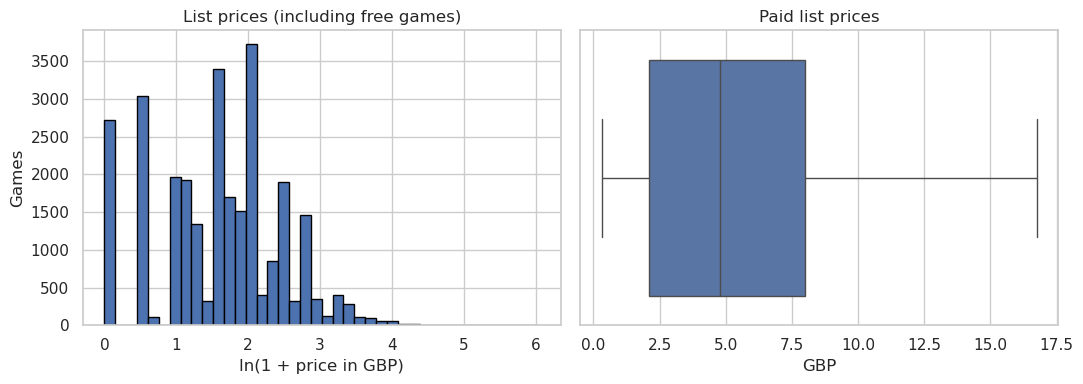

Free share among games with known price: 9.6 %


count    25511.00
mean         6.94
std          9.33
min          0.32
25%          2.09
50%          4.79
75%          7.99
max        421.99
Name: price_gbp, dtype: float64

In [44]:
paid = games.loc[games["price_gbp"] > 0, "price_gbp"]
known_price = games["price_gbp"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(known_price), bins=40, edgecolor="black")
axes[0].set(title="List prices (including free games)", xlabel="ln(1 + price in GBP)", ylabel="Games")
sns.boxplot(x=paid, showfliers=False, ax=axes[1])
axes[1].set(title="Paid list prices", xlabel="GBP")
plt.tight_layout()
plt.show()
print("Free share among games with known price:", round(100 * known_price.eq(0).mean(), 1), "%")
display(paid.describe().round(2))


### Recenze: kolik jich je a jak jsou pozitivní?


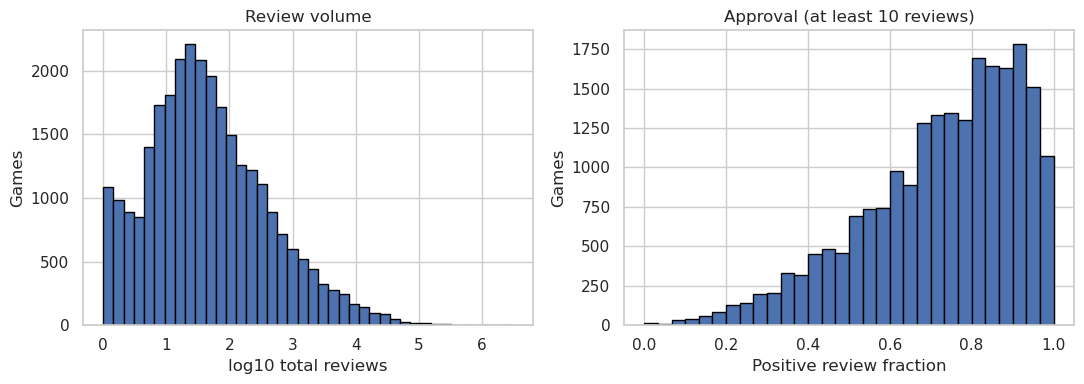

Median reviews among reviewed games: 35.0
Median approval among games with >=10 reviews: 0.7619047619047619


In [45]:
reviewed = games.loc[games["review_total"] > 0, "review_total"]
approval = games.loc[games["review_total"] >= 10, "positive_share"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log10(reviewed), bins=40, edgecolor="black")
axes[0].set(title="Review volume", xlabel="log10 total reviews", ylabel="Games")
axes[1].hist(approval, bins=30, edgecolor="black")
axes[1].set(title="Approval (at least 10 reviews)", xlabel="Positive review fraction", ylabel="Games")
plt.tight_layout()
plt.show()
print("Median reviews among reviewed games:", reviewed.median())
print("Median approval among games with >=10 reviews:", approval.median())


Mezi hrami s alespoň jednou recenzí byl v původním běhu medián **35 recenzí**.
Několik titulů s velkým množstvím recenzí vytváří dlouhý pravý chvost rozdělení.
U her s alespoň 10 recenzemi byl medián podílu kladných recenzí **76,2 %**.
Tato hranice omezuje situace, kdy by jediná kladná recenze působila jako silný důkaz všeobecné spokojenosti.
Hodnocení popisuje názory recenzentů, nikoli všech hráčů.


### Doba hraní: jaké hodnoty jsou vykázány a jak často jsou nulové?


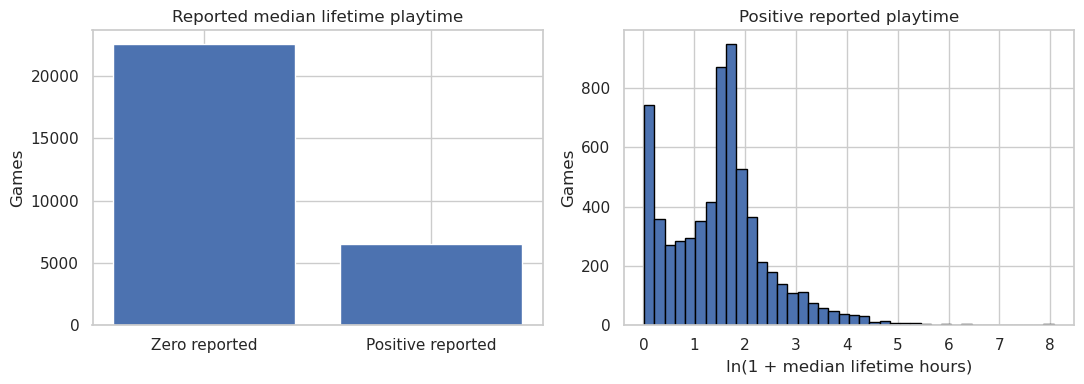

Zero reported: 77.5 %
Typical positive reported playtime [hours]: 3.783333333333333


In [46]:
observed = games.loc[games["median_forever"] > 0, "median_forever"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Zero reported", "Positive reported"], [games["median_forever"].eq(0).sum(), len(observed)])
axes[0].set(title="Reported median lifetime playtime", ylabel="Games")
axes[1].hist(np.log1p(observed / 60), bins=40, edgecolor="black")
axes[1].set(title="Positive reported playtime", xlabel="ln(1 + median lifetime hours)", ylabel="Games")
plt.tight_layout()
plt.show()
print("Zero reported:", round(100 * games["median_forever"].eq(0).mean(), 1), "%")
print("Typical positive reported playtime [hours]:", observed.median() / 60)


V původních výsledcích mělo **77,5 %** her nulový vykázaný medián doby hraní.
U zbývajících her byl medián přibližně **3,8 hodiny**. Samotná nula neumožňuje rozlišit
chybějící či nedostatečné měření od skutečně velmi krátké doby hraní.
Proto do shlukování založeného na době hraní zahrnuji pouze kladné hodnoty.
Tato volba výrazně ovlivňuje výběr analyzovaných her; nedokazuje, že každá nula znamená chybějící údaj.


### Kategorie: jaké typy záznamů jsou zastoupeny?


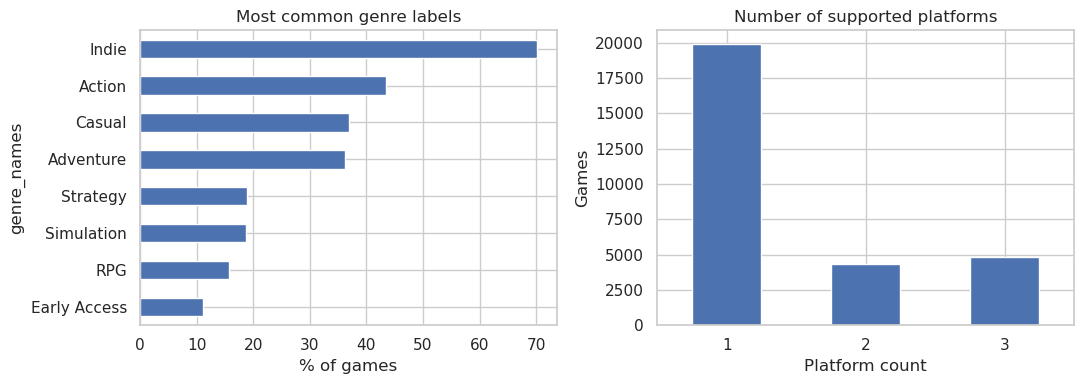

In [47]:
genre_share = games.explode("genre_names")["genre_names"].value_counts() / len(games) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
genre_share.head(8).sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Most common genre labels", xlabel="% of games")
games["platform_count"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Number of supported platforms", xlabel="Platform count", ylabel="Games")
plt.tight_layout()
plt.show()


V původním katalogu patřily mezi častá označení Indie (přibližně 70 %) a Action (přibližně 43 %).
Jedna hra může mít více označení, proto se procenta žánrů nemusí sečíst na 100 %.
Přibližně 68 % her podporovalo hlavně jen jednu platformu.


### Vztahy mezi proměnnými: souvisejí popularita, doba hraní, cena a hodnocení?


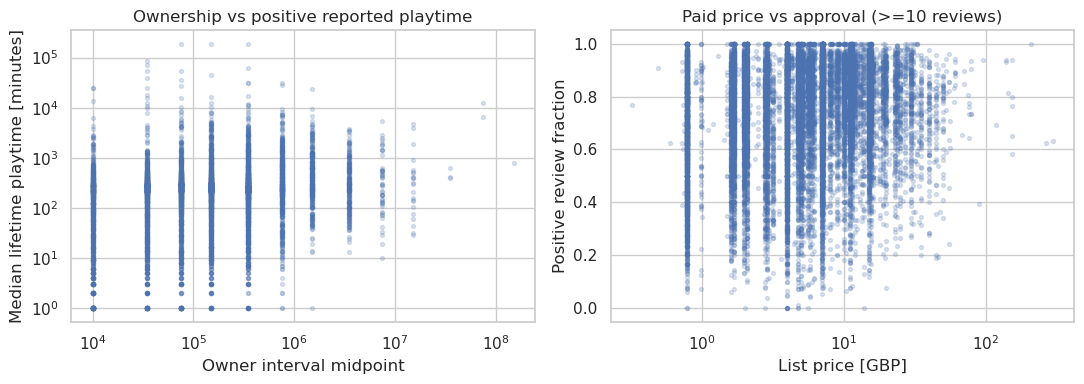

Ownership–playtime Spearman: 0.2358832370766268
Price–approval Spearman: 0.16787881668062957


In [48]:
observed_games = games.loc[games["median_forever"] > 0]
paid_reviewed = games.loc[(games["price_gbp"] > 0) & (games["review_total"] >= 10)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(observed_games["owners_midpoint"], observed_games["median_forever"], s=8, alpha=0.2)
axes[0].set(xscale="log", yscale="log", title="Ownership vs positive reported playtime",
            xlabel="Owner interval midpoint", ylabel="Median lifetime playtime [minutes]")
axes[1].scatter(paid_reviewed["price_gbp"], paid_reviewed["positive_share"], s=8, alpha=0.2)
axes[1].set(xscale="log", title="Paid price vs approval (>=10 reviews)",
            xlabel="List price [GBP]", ylabel="Positive review fraction")
plt.tight_layout()
plt.show()
print("Ownership–playtime Spearman:", observed_games[["owners_midpoint", "median_forever"]].corr(method="spearman").iloc[0, 1])
print("Price–approval Spearman:", paid_reviewed[["price_gbp", "positive_share"]].corr(method="spearman").iloc[0, 1])


V původním běhu byla Spearmanova korelace mezi počtem vlastníků a dobou hraní **0,24**
u her s kladnou vykázanou dobou hraní. Populárnější hry tedy neměly soustavně výrazně delší dobu hraní.
Korelace mezi cenou a podílem kladných recenzí byla **0,17** u placených her s alespoň 10 recenzemi.
Jde o slabé kladné souvislosti; žádná z nich nedokazuje, že vyšší cena způsobuje lepší hodnocení
nebo že vyšší počet vlastníků způsobuje delší dobu hraní.
Upravený graf hodnocení používá stejnou minimální hranici počtu recenzí jako vypisovaná korelace.


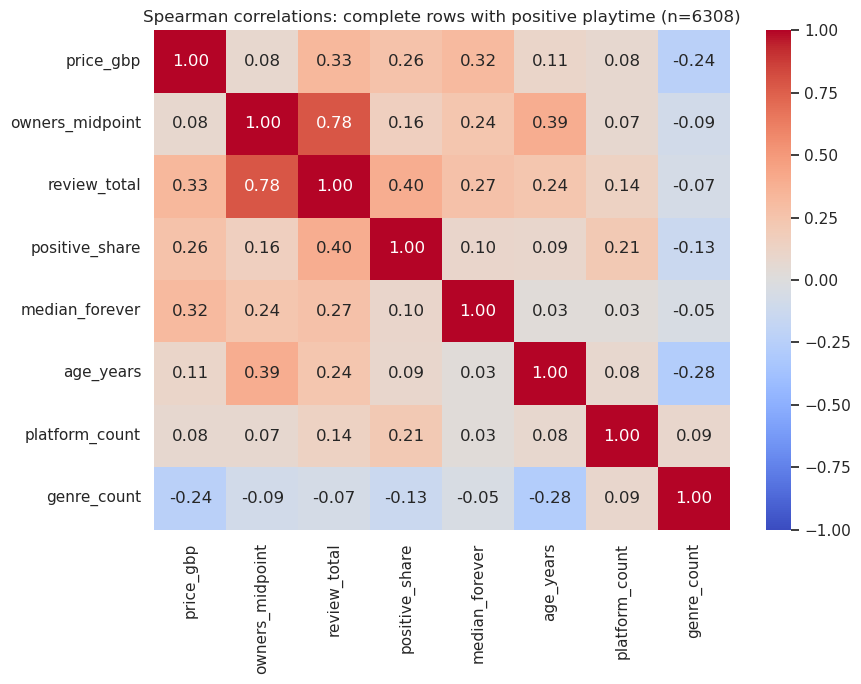

In [49]:
corr_columns = ["price_gbp", "owners_midpoint", "review_total", "positive_share",
                "median_forever", "age_years", "platform_count", "genre_count"]
corr_input = games.loc[games["median_forever"] > 0, corr_columns].dropna()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_input.corr(method="spearman"), annot=True, fmt=".2f",
            vmin=-1, vmax=1, center=0, cmap="coolwarm")
plt.title(f"Spearman correlations: complete rows with positive playtime (n={len(corr_input)})")
plt.tight_layout()
plt.show()


### Odlehlé hodnoty: nejprve zkontrolovat, potom případně odstranit

Vysoká cena nebo dlouhá doba hraní může být platný údaj, neobvyklé chování nebo chyba měření.
Označení pomocí pravidla IQR je důvod ke kontrole, nikoli automatický důkaz chyby.
Pravidlo aplikuji na kladné hodnoty, aby se neopakoval původní problém s nulovým IQR u doby hraní.


In [50]:
outlier_rows = []
for column in ["price_gbp", "median_forever"]:
    positive = games.loc[games[column] > 0, column]
    values = np.log1p(positive)
    q1, q3 = values.quantile([0.25, 0.75]) # type: ignore
    iqr = q3 - q1
    flags = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_rows.append({"variable": column, "positive_reports": len(values), "IQR_flags": flags.sum()})
    display(games.nlargest(3, column)[["name", column]])
display(pd.DataFrame(outlier_rows))


,name,price_gbp
22674,ADR-Labelling Game,421.99
26541,Marvelous Designer 8 for Steam,307.20
14018,GameMaker Studio 2 UWP,303.99


,name,median_forever
9927,The Abbey of Crime Extensum,190625
1636,The Banner Saga: Factions,190489
6513,The Secret of Tremendous Corporation,190445


,variable,positive_reports,IQR_flags
0,price_gbp,25511,176
1,median_forever,6547,548


Mezi původní extrémy patřila ceníková cena přibližně **422 £** a medián celkové doby hraní **190 625 minut**.
Některé drahé položky představovaly software; ten je z výběru her vyloučen samostatně.
Zbývající extrémní doby hraní si zaslouží kontrolu a nelze je bez dalšího označit za správné.
Další odstraňování krajních hodnot zde nepoužívám, protože nemám dostatek důkazů pro určení konkrétních chyb.
Logaritmické transformace jejich vliv snižují, ale neodstraňují; `StandardScaler` je na odlehlé hodnoty stále citlivý.


## 4. Výběr her pro shlukování

Používám vydané hry se známou cenou, dostupnými počty žánrů a platforem, alespoň jedním herním žánrem,
kladným vykázaným mediánem doby hraní a alespoň **10 recenzemi**.
Hranice deseti recenzí je praktické pravidlo pro základní množství podkladů, nikoli matematicky určené optimum.
Tabulka ukazuje, kolik her zbývá po jednotlivých filtrech. Při porovnávání hranic počtu recenzí zůstávají ostatní filtry stejné.


In [51]:
filters = {
    "Released by reference date": games["release_date_parsed"].notna()
        & games["coming_soon"].eq(False)
        & games["release_date_parsed"].le(REFERENCE_DATE),
    "Known GBP price": games["price_gbp"].notna(),
    "Known characteristics": games["genre_count"].notna() & games["platform_count"].notna(),
    "Entertainment genre": games["is_entertainment"],
    "Positive reported playtime": games["median_forever"] > 0,
}
keep = pd.Series(True, index=games.index)
counts = []
for description, mask in filters.items():
    keep &= mask
    counts.append({"filter": description, "remaining": int(keep.sum())})

display(pd.Series({threshold: int((keep & games["review_total"].ge(threshold)).sum())
                   for threshold in [0, 1, 5, 10, 20]}, name="games by minimum review count"))
keep &= games["review_total"].ge(10)
counts.append({"filter": "At least 10 reviews", "remaining": int(keep.sum())})
cohort = games.loc[keep].copy()
display(pd.DataFrame(counts))
print(f"Final cohort: {len(cohort)} / {len(games)} ({len(cohort)/len(games):.1%})")


0     6256
1     6255
5     6244
10    6216
20    6104
Name: games by minimum review count, dtype: int64

,filter,remaining
0,Released by reference date,28650
1,Known GBP price,28098
2,Known characteristics,28060
3,Entertainment genre,27627
4,Positive reported playtime,6256
5,At least 10 reviews,6216


Final cohort: 6216 / 29078 (21.4%)


Původní konečný výběr obsahoval **6 216 her**, tedy pouze **21,4 %** spárovaného katalogu.
Nejvíce her bylo vyřazeno kvůli požadavku na kladnou dobu hraní.
Výsledné shluky proto popisují tuto vybranou podmnožinu, nikoli celý trh na Steamu,
zejména ne hry s malým množstvím naměřené aktivity.


## 5. Příprava sedmi příznaků

Používám jeden příznak popularity, počet vlastníků. Současným zařazením počtu vlastníků i počtu recenzí
by popularita mohla získat zbytečně velkou váhu. Dále používám dobu hraní, podíl kladných recenzí,
cenu, stáří hry a dva počty z metadat. Tyto počty nevyjadřují konkrétní žánr.

- `log1p(x) = ln(1+x)` stlačuje zešikmené škály počtu vlastníků, doby hraní a ceny; umožňuje také zpracovat nulové ceny.
- Vyhlazený podíl kladných recenzí `(positive + 1) / (total + 2)` mírně posouvá hodnocení s malým počtem recenzí směrem k 0,5.
  Jde o odhad použitý v modelu; v následných profilech shluků uvádím původní pozorovaný podíl.
- Standardizace používá `z = (x − průměr) / směrodatná odchylka`, aby vzdálenosti nebyly určovány samotnými
  velikostmi hodnot v různých jednotkách, například minutách a librách. Sjednocení rozptylů je vědomou volbou vah příznaků.

Obě metody dostávají **stejné řádky a stejných sedm příznaků**.
Nejde o učení s učitelem: není zde cílová proměnná ani testovací skóre predikce.


In [52]:
cohort["log_owners_mid"] = np.log1p(cohort["owners_midpoint"])
cohort["log_playtime"] = np.log1p(cohort["median_forever"])
cohort["log_price_gbp"] = np.log1p(cohort["price_gbp"])
cohort["approval_smooth"] = (cohort["positive"] + 1) / (cohort["review_total"] + 2)
features = ["log_owners_mid", "log_playtime", "approval_smooth", "log_price_gbp",
            "age_years", "platform_count", "genre_count"]
X = pd.DataFrame(StandardScaler().fit_transform(cohort[features]),
                 columns=features, index=cohort.index)
assert np.isfinite(X.to_numpy()).all()
assert X.std().gt(0).all()
print("Clustering matrix:", X.shape)


Clustering matrix: (6216, 7)


## 6. K-means: výběr a interpretace počtu shluků

K-means střídavě přiřazuje každou hru k nejbližšímu centroidu a přepočítává polohy centroidů.

**Inertia** označuje tento součet. S rostoucím počtem shluků klesá, takže samotná nejnižší hodnota neurčuje vhodné `k`.
Metoda lokte hledá bod, za kterým další shluky přinášejí podstatně menší zlepšení.

**Siluetový koeficient (silhouette)** porovnává průměrnou vzdálenost hry k ostatním hrám ve vlastním shluku, $a(i)$,
s nejnižší průměrnou vzdáleností k hrám v některém jiném shluku, $b(i)$

Hodnoty blízké 1 ukazují lepší oddělení; hodnoty kolem 0 naznačují překryv.
Záporné hodnoty naznačují, že by hra mohla lépe zapadat do jiného shluku.
Porovnávám `k=2…8` a skóre počítám na pevném vzorku nejvýše 2 000 her.
Samotné modely jsou stále vytvořeny nad všemi hrami vybrané podmnožiny.
Volím nejvyšší průměrný siluetový koeficient; průběh lokte a velikosti shluků slouží jako další podklady.
Původní pomocná pravidla minimální velikosti 5 % a tolerance skóre 0,005 byla odstraněna, aby byl výběr jednodušší na vysvětlení.


,k,inertia,silhouette,smallest_cluster
0,2,35824.6564,0.1669,3014
1,3,31578.5931,0.1649,1207
2,4,28204.7785,0.1734,905
3,5,25702.2431,0.1808,829
4,6,23859.5353,0.1798,723
5,7,22427.6773,0.1771,612
6,8,21360.8209,0.1667,585


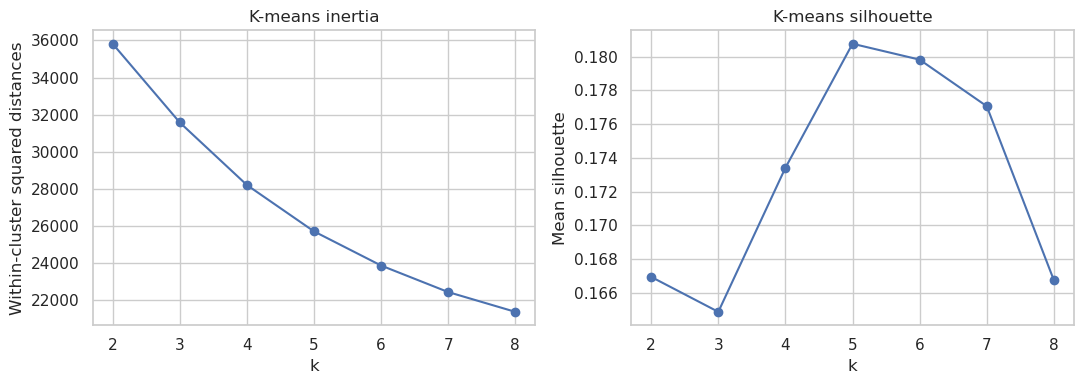

Selected k: 5


In [53]:
eval_index = X.sample(n=min(2000, len(X)), random_state=SEED).index


def score_partition(labels):
    return silhouette_score(X.loc[eval_index], labels.loc[eval_index])


km_models = {}
rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = pd.Series(model.fit_predict(X), index=X.index)
    km_models[k] = (model, labels)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": score_partition(labels),
                 "smallest_cluster": int(labels.value_counts().min())})
km_scores = pd.DataFrame(rows)
KM_K = int(km_scores.loc[km_scores["silhouette"].idxmax(), "k"]) # type: ignore
km_model, km_labels = km_models[KM_K]
display(km_scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(km_scores["k"], km_scores["inertia"], marker="o")
axes[0].set(title="K-means inertia", xlabel="k", ylabel="Within-cluster squared distances")
axes[1].plot(km_scores["k"], km_scores["silhouette"], marker="o")
axes[1].set(title="K-means silhouette", xlabel="k", ylabel="Mean silhouette")
plt.tight_layout()
plt.show()
print("Selected k:", KM_K)


V dodaném běhu nebyl patrný výrazný loket. Siluetový koeficient dosáhl maxima pro **k=5, 0,1808**;
výsledek pro `k=6` byl téměř stejný, **0,1798**.
Pět shluků je proto obhajitelná pracovní volba mezi testovanými možnostmi.


## 7. Hierarchické shlukování Wardovou metodou

Wardova metoda začíná samostatným shlukem pro každou hru a opakovaně spojuje dvojici,
jejíž sloučení způsobí nejmenší nárůst součtu čtverců odchylek uvnitř shluků.
Dendrogram zaznamenává tato spojení; jeho řezem vzniká zvolený počet skupin.
Na rozdíl od K-means metoda opakovaně nepřiřazuje hry k pevnému počtu centroidů.
Obě metody přesto při zvolené reprezentaci a eukleidovské vzdálenosti upřednostňují kompaktní shluky.

Vytvářím jeden strom nad stejným úplným výběrem her, řežu jej pro `k=2…8`
a používám stejný vzorek pro výpočet siluetového koeficientu.
Pro přibližně 6 200 řádků je tento postup zvládnutelný, plné hierarchické shlukování má ale kvadratickou paměťovou náročnost.


,k,silhouette,smallest_cluster
0,2,0.1448,2424
1,3,0.1357,706
2,4,0.1349,706
3,5,0.1444,616
4,6,0.1425,616
5,7,0.1270,577
6,8,0.1144,318


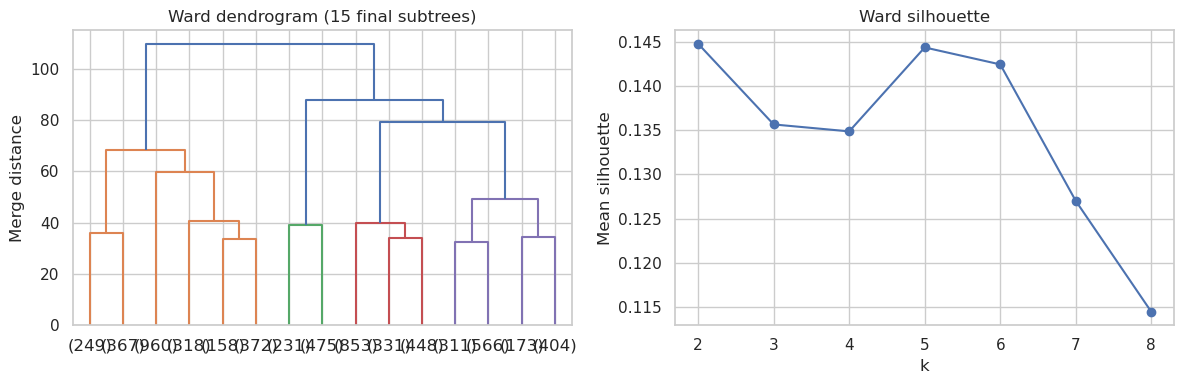

Selected k: 2
Partition agreement (ARI): 0.21323918498232922


Ward,0,1
K-means,,
0,183,1395
1,239,1269
2,34,817
3,1263,187
4,705,124


In [54]:
Z = linkage(X.to_numpy(), method="ward")
ward_partitions = {}
rows = []
for k in range(2, 9):
    labels = pd.Series(fcluster(Z, t=k, criterion="maxclust") - 1, index=X.index)
    ward_partitions[k] = labels
    rows.append({"k": k, "silhouette": score_partition(labels),
                 "smallest_cluster": int(labels.value_counts().min())})
ward_scores = pd.DataFrame(rows)
WARD_K = int(ward_scores.loc[ward_scores["silhouette"].idxmax(), "k"]) # type: ignore
ward_labels = ward_partitions[WARD_K]
display(ward_scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=15, ax=axes[0])
axes[0].set(title="Ward dendrogram (15 final subtrees)", ylabel="Merge distance")
axes[1].plot(ward_scores["k"], ward_scores["silhouette"], marker="o")
axes[1].set(title="Ward silhouette", xlabel="k", ylabel="Mean silhouette")
plt.tight_layout()
plt.show()
print("Selected k:", WARD_K)
print("Partition agreement (ARI):", adjusted_rand_score(km_labels, ward_labels))
display(pd.crosstab(km_labels.rename("K-means"), ward_labels.rename("Ward")))


V dodaném běhu Wardova metoda vybrala **k=2 se siluetovým koeficientem 0,1448**.
Výsledek pro `k=5` (**0,1444**) byl téměř shodný, takže podpora pro dva shluky je slabá.
K-means dosáhl při této reprezentaci vyššího siluetového koeficientu.

Původní kontingenční tabulka ukázala částečnou shodu: shluky K-means 0–2 většinou patřily do Wardova shluku 1,
zatímco shluky 3–4 většinou do Wardova shluku 0. V každé skupině se však objevovaly výjimky.
Rozdělení jsou tedy **částečně sladěná**, nikoli přesně vnořená.
Upravený Randův index (ARI) byl **0,2132**; vyjadřuje shodu rozdělení, nikoli přesnost.
Rozdílné počty shluků tuto shodu ovlivňují, ale samy o sobě nevysvětlují všechny rozdíly.


## 8. Popis shluků v původních jednotkách

Názvy skupin mají vycházet z jejich naměřených profilů. Čísla shluků jsou pouze identifikátory, nikoli pořadí kvality.
Pro interpretaci uvádím mediány v librách, hodinách a letech; standardizované souřadnice nelze číst jako původní hodnoty.


K-means profiles:


,games,price_gbp,owners_midpoint,lifetime_playtime_hours,approval,age_years,platform_count,genre_count
cluster,,,,,,,,
0,1578,6.99,150000.0,4.28,0.84,3.63,3.0,3.0
1,1508,10.99,75000.0,4.97,0.82,2.66,1.0,2.0
2,851,6.99,350000.0,3.45,0.84,8.64,1.0,1.0
3,1450,0.79,150000.0,4.02,0.56,2.80,1.0,3.0
4,829,1.59,35000.0,0.13,0.73,2.26,1.0,3.0


Ward profiles:


,games,price_gbp,owners_midpoint,lifetime_playtime_hours,approval,age_years,platform_count,genre_count
cluster,,,,,,,,
0,2424,0.79,75000.0,2.58,0.67,2.72,1.0,3.0
1,3792,7.19,150000.0,4.50,0.82,3.79,2.0,2.0


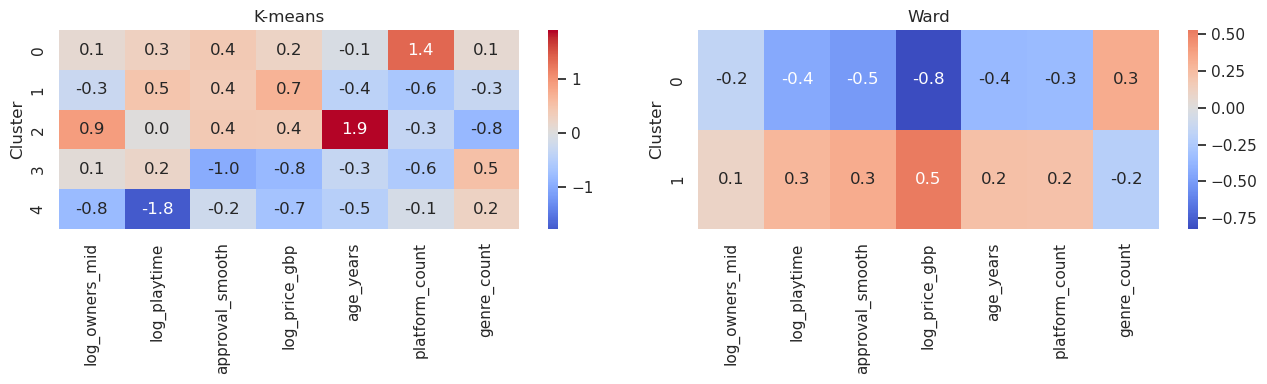

In [55]:
def profile(labels):
    frame = cohort.assign(cluster=labels, playtime_hours=cohort["median_forever"] / 60)
    return frame.groupby("cluster").agg(
        games=("steam_appid", "size"),
        price_gbp=("price_gbp", "median"),
        owners_midpoint=("owners_midpoint", "median"),
        lifetime_playtime_hours=("playtime_hours", "median"),
        approval=("positive_share", "median"),
        age_years=("age_years", "median"),
        platform_count=("platform_count", "median"),
        genre_count=("genre_count", "median"),
    )


print("K-means profiles:")
display(profile(km_labels).round(2))
print("Ward profiles:")
display(profile(ward_labels).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, labels, name in [(axes[0], km_labels, "K-means"), (axes[1], ward_labels, "Ward")]:
    means = X.assign(cluster=labels).groupby("cluster").mean()
    sns.heatmap(means, center=0, cmap="coolwarm", annot=True, fmt=".1f", ax=ax)
    ax.set(title=name, xlabel="", ylabel="Cluster")
plt.tight_layout()
plt.show()


Teplotní mapy ukazují relativní profily příznaků: kladná hodnota znamená,
že průměr shluku leží u daného transformovaného příznaku nad průměrem vybrané podmnožiny.
Pro popis skutečných cen, doby hraní a hodnocení je nutné použít tabulky v původních jednotkách.
Původní profily se lišily cenou, stářím, hodnocením i dobou hraní;
nelze je proto redukovat na jediné pořadí popularity.


### Zobrazení shluků: stejné hry obarvené podle obou metod

Každá hra je popsána sedmi příznaky, které nelze současně zobrazit v rovinném grafu.
**Analýza hlavních komponent (PCA)** vytváří dvě souřadnice zachovávající co největší část rozptylu těchto příznaků.
Oba grafy používají stejné souřadnice i rozsahy os; mění se pouze barvy podle příslušnosti ke shlukům.

Shlukování proběhlo v plném prostoru sedmi příznaků. PCA slouží pouze k zobrazení již vypočtených přiřazení.
Popisky os uvádějí, jakou část původního rozptylu jednotlivé komponenty zachovávají.
Čísla shluků jsou libovolná a platí pro každou metodu samostatně.


Variation shown in 2D: 44.5%; omitted: 55.5%


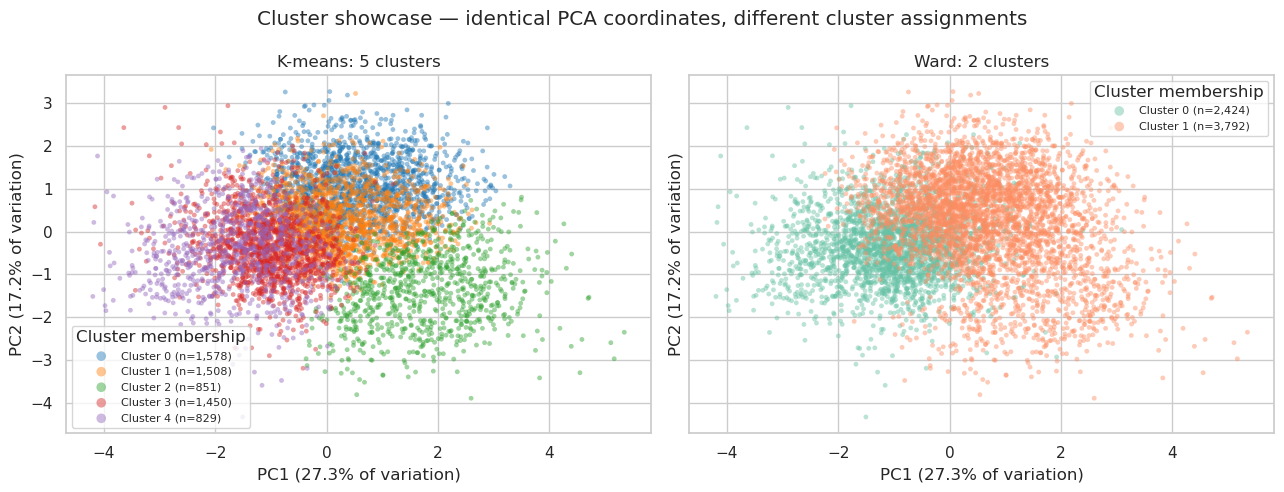

In [56]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, svd_solver="full")
coordinates = pd.DataFrame(pca.fit_transform(X), columns=["PC1", "PC2"], index=X.index)
variance = pca.explained_variance_ratio_
print(f"Variation shown in 2D: {variance.sum():.1%}; omitted: {1 - variance.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, method, palette in [
    (axes[0], km_labels, "K-means", "tab10"),
    (axes[1], ward_labels, "Ward", "Set2"),
]:
    cluster_ids = sorted(labels.unique())
    colours = sns.color_palette(palette, n_colors=len(cluster_ids))
    for cluster_id, colour in zip(cluster_ids, colours):
        points = coordinates.loc[labels.eq(cluster_id)]
        ax.scatter(points["PC1"], points["PC2"], s=12, alpha=0.45,
                   color=colour, edgecolors="none",
                   label=f"Cluster {cluster_id} (n={len(points):,})")
    ax.set(title=f"{method}: {len(cluster_ids)} clusters",
           xlabel=f"PC1 ({variance[0]:.1%} of variation)",
           ylabel=f"PC2 ({variance[1]:.1%} of variation)")
    ax.legend(title="Cluster membership", fontsize=8, markerscale=2)

fig.suptitle("Cluster showcase — identical PCA coordinates, different cluster assignments")
plt.tight_layout()
plt.show()


**Jak graf číst:** Každý bod představuje jednu hru a jeho barva označuje přiřazený shluk.
Blízké body mají podobné profily v zobrazené projekci. Lze porovnat, jak K-means rozděluje body do jemnějších skupin
a jak Wardova metoda vytváří širší skupiny. Význam jednotlivých shluků určují jejich profilové tabulky.

V původní uložené analýze zachovávaly první dvě komponenty přibližně **45 %** rozptylu sedmi příznaků.
Graf zobrazoval překrývající se oblasti, nikoli izolované skupiny. Po opětovném spuštění ověřte vypsané procento i nové grafy.
Původní nízké siluetové koeficienty rovněž naznačují slabé oddělení v plném prostoru příznaků.

Převod do 2D část informací zahazuje: překryv v grafu sám o sobě nedokazuje překryv ve všech sedmi dimenzích
a viditelné oddělení nepotvrzuje platnost shluků. PC1 a PC2 kombinují několik příznaků;
ani jedna osa proto nepředstavuje jednoduše „cenu“ nebo „popularitu“.
Stejné barvy a číselné identifikátory neoznačují automaticky odpovídající skupiny napříč metodami.


### Referenční interpretace z dodaného běhu

Tyto identifikátory a hodnoty popisují původní uložený běh. Po opětovném spuštění je ověřte;
číselná označení se mohou změnit. Počty vlastníků níže představují středy intervalů, nikoli ověřené počty.
„Doba hraní“ je medián napříč hrami z jejich vykázaných mediánů celkové doby hraní.

| Shluk K-means | Počet her | Medián ceny | Střed intervalu vlastníků | Doba hraní | Kladné recenze | Interpretace |
|---|---:|---:|---:|---:|---:|---|
| 0 | 1 578 | 6,99 £ | 150 tis. | 4,3 h | 84 % | Hry se střední cenou a kladným hodnocením |
| 1 | 1 508 | 10,99 £ | 75 tis. | 5,0 h | 82 % | Dražší hry vzhledem k vybrané podmnožině |
| 2 | 851 | 6,99 £ | 350 tis. | 3,5 h | 84 % | Starší, rozšířenější hry; medián stáří 8,6 roku |
| 3 | 1 450 | 0,79 £ | 150 tis. | 4,0 h | 56 % | Levné hry s nižším podílem kladných recenzí |
| 4 | 829 | 1,59 £ | 35 tis. | 0,13 h | 73 % | Levné hry s krátkou vykázanou celkovou dobou hraní |

Vydavatel by mohl shluky využít jako srovnávací skupiny: například dražší hru porovnat se shlukem 1
při posuzování jejího postavení na trhu. U shluku 3 dává smysl vedle ceny zkoumat také zpětnou vazbu hráčů.
Jde o možné využití výsledků, nikoli důkaz, že slevy, balíčky nebo reklama zlepší výsledky hry.
Osm minut celkové doby hraní ve shluku 4 neznamená osmiminutová herní sezení.

Původní dva Wardovy shluky byly širší: shluk 0 měl medián ceny **0,79 £** a podíl kladných recenzí **67 %**,
zatímco shluk 1 měl **7,19 £** a **82 %**.
V rámci vybrané podmnožiny tak popisují levnější a hůře hodnocené hry oproti dražším a lépe hodnoceným hrám.


## 9. Závěr

Vybrané hry lze uspořádat do popsatelných skupin, jejich oddělení je však slabé.
V dodaném běhu vycházelo nejlépe pět shluků K-means se siluetovým koeficientem **0,181**
a dva shluky Wardovy metody s hodnotou **0,145**.
Jejich naměřené profily lze interpretovat, ale žádné z těchto skóre nedokazuje,
že jde o objektivně správné segmenty trhu.

Hlavní omezení:

- Do shlukování vstoupilo pouze **6 216 z 29 078** spárovaných her; výběr výrazně ovlivňuje požadavek na kladnou dobu hraní.
- Počty vlastníků jsou uvedeny v hrubých intervalech. Odhady doby hraní, extrémní hodnoty a výběr lidí, kteří píší recenze, přinášejí další nejistotu.
- Cena, stáří a vlastnosti hry spolu mohou souviset, aniž by jedna proměnná způsobovala druhou.
- Výsledky nepopisují současný Steam.
- Volba příznaků, logaritmických transformací a standardizace určuje, co znamená „podobnost“. Počty žánrů a platforem nezachovávají jejich konkrétní identitu.
- Oba algoritmy upřednostňují kompaktní skupiny. Siluetový koeficient je vnitřní ukazatel kvality rozdělení, nikoli nezávislé ověření jeho platnosti.